Re-run this notebook from anywhere inside the repository with:

```bash
(cd "$(git rev-parse --show-toplevel)" && uv run --no-project --with jupyter --with pyyaml --with pandas --with numpy --with scipy --with matplotlib --with openai --with python-dotenv --with requests jupyter nbconvert --to notebook --execute --inplace explorations/notebooks/02_input_eda.ipynb)
```

# 02 · Input EDA and a metadata retriever prototype

**Inputs only.** Receipts are loaded through `explorations/lib/receipts_safe.py`, which deletes
`labels`, `line_items[].labels` and `notes` right after `json.loads`. Nothing here reads,
counts or summarises an answer, and nothing is evaluated against one.

To keep this notebook safe to share, raw item descriptions are never printed in full: only
their language, length and counts.

In [1]:
from __future__ import annotations

import json
import re
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "policy-docs").is_dir())
EXP = REPO / "explorations"
sys.path.insert(0, str(EXP / "lib"))
from receipts_safe import assert_clean, load_inputs

receipts = load_inputs()
assert_clean(receipts)
print(
    f"{len(receipts)} receipts, {sum(len(r['line_items']) for r in receipts)} line items; answer keys removed"
)
print("receipt fields:", sorted(receipts[0]))
print("line fields:", sorted(receipts[0]["line_items"][0]))

32 receipts, 79 line items; answer keys removed
receipt fields: ['attendee_count', 'currency', 'employee_country', 'employee_id', 'entity', 'fx_rate_to_usd', 'itemized', 'line_items', 'mcc', 'mcc_description', 'merchant_name', 'pre_approval_ref', 'receipt_id', 'submitted_expense_type', 'total_amount', 'total_amount_usd', 'transaction_datetime', 'trip_id', 'trip_nights']
line fields: ['amount', 'amount_usd', 'description_raw', 'language', 'line_id', 'quantity', 'unit_price']


In [2]:
R = pd.DataFrame([{k: v for k, v in r.items() if k != "line_items"} for r in receipts])
R["n_items"] = [len(r["line_items"]) for r in receipts]
R["dt"] = pd.to_datetime(R["transaction_datetime"])
R["date"] = R["dt"].dt.date
L = pd.DataFrame(
    [
        {
            "receipt_id": r["receipt_id"],
            **{k: v for k, v in i.items() if k != "description_raw"},
            "desc_len": len(i["description_raw"]),
        }
        for r in receipts
        for i in r["line_items"]
    ]
)
R.drop(columns=["dt"]).head(3)

,receipt_id,employee_id,employee_country,entity,submitted_expense_type,merchant_name,mcc,mcc_description,transaction_datetime,currency,fx_rate_to_usd,total_amount,total_amount_usd,attendee_count,trip_id,trip_nights,pre_approval_ref,itemized,n_items,date
0,RCP-001,E-1042,US,GLOBAL,Meals - Individual,Harvest Table Kitchen,5812,Eating places and restaurants,2026-04-14T19:22:00,USD,1.0,48.20,48.20,NaN,TRIP-0091,3.0,NaN,True,4,2026-04-14
1,RCP-002,E-1042,US,GLOBAL,Client Entertainment,Verona Grill,5812,Eating places and restaurants,2026-04-16T19:45:00,USD,1.0,234.00,234.00,4.0,TRIP-0091,3.0,PA-2026-0412,True,3,2026-04-16
2,RCP-003,E-1067,US,GLOBAL,Office Supplies,Cornerstone Office Supply,5943,Office and stationery supply,2026-04-10T11:05:00,USD,1.0,41.47,41.47,NaN,NaN,NaN,NaN,True,3,2026-04-10


## Entity, country, currency and FX

currency,EUR,INR,JPY,USD
entity,,,,
APAC,0,1,1,0
EMEA,3,0,0,0
GLOBAL,0,0,0,27


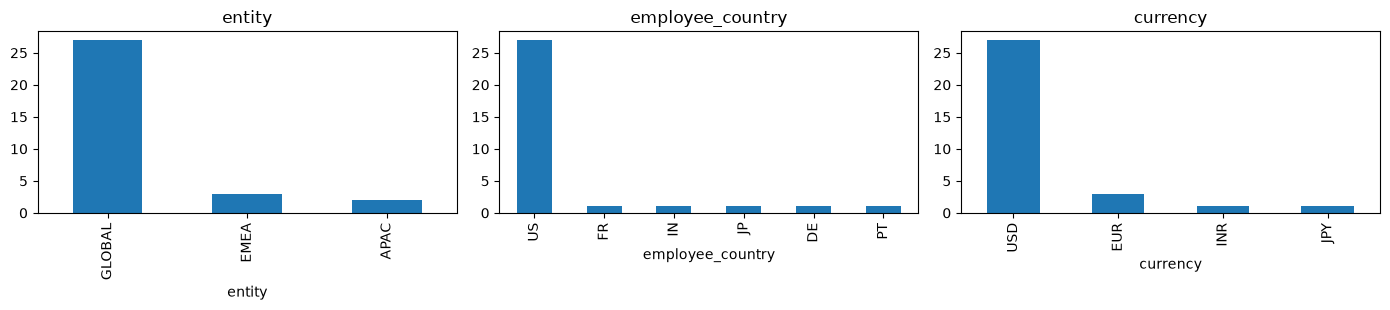

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.2))
R["entity"].value_counts().plot.bar(ax=axes[0], title="entity")
R["employee_country"].value_counts().plot.bar(ax=axes[1], title="employee_country")
R["currency"].value_counts().plot.bar(ax=axes[2], title="currency")
plt.tight_layout()
pd.crosstab(R["entity"], R["currency"])

In [4]:
fx = R.groupby("currency")["fx_rate_to_usd"].agg(["count", "min", "max", "nunique"])
print("FX rate per currency (rate multiplies the receipt amount into USD):")
fx

FX rate per currency (rate multiplies the receipt amount into USD):


,count,min,max,nunique
currency,,,,
EUR,3,1.0800,1.0800,1
INR,1,0.0120,0.0120,1
JPY,1,0.0067,0.0067,1
USD,27,1.0000,1.0000,1


In [5]:
# Consistency of the conversion: total_amount * fx_rate_to_usd versus total_amount_usd.
R["usd_check"] = (R["total_amount"] * R["fx_rate_to_usd"] - R["total_amount_usd"]).abs()
print("max |total * rate - total_usd|:", round(R["usd_check"].max(), 4))
L["line_check"] = (L["quantity"] * L["unit_price"] - L["amount"]).abs()
print("max |qty * unit_price - amount|:", round(L["line_check"].max(), 4))
sums = L.groupby("receipt_id")["amount"].sum()
R["items_minus_total"] = R["receipt_id"].map(sums) - R["total_amount"]
print(
    "receipts whose line amounts do not add up to the total:",
    int((R["items_minus_total"].abs() > 0.01).sum()),
)

max |total * rate - total_usd|: 0.0
max |qty * unit_price - amount|: 0.0
receipts whose line amounts do not add up to the total: 0


## Expense type, MCC and risk tier

The risk tier comes from the table in `merchant-category-risk.md`, parsed here. Any MCC not in
the table is low risk.

In [6]:
mcc_text = (REPO / "data" / "policy-docs" / "merchant-category-risk.md").read_text()
MCC_TIER = {
    int(m): t.strip("* ").lower()
    for m, t in re.findall(r"^\| (\d{4}) \| [^|]+ \| ([^|]+) \|", mcc_text, re.M)
}
R["mcc_tier"] = R["mcc"].map(lambda m: MCC_TIER.get(int(m), "low (unlisted)"))
pd.crosstab(R["submitted_expense_type"], R["mcc_tier"], margins=True)

mcc_tier,high,low,medium,All
submitted_expense_type,,,,
Client Entertainment,1,4,0,5
Client Gifts,1,0,1,2
Computer Equipment,0,2,1,3
Lodging,1,1,0,2
Meals - Individual,0,7,1,8
Meals - Team,0,4,0,4
Office Supplies,0,1,2,3
Software,0,1,0,1
Travel - Other,0,2,2,4


In [7]:
R.groupby(["mcc", "mcc_description", "mcc_tier"]).size().rename("receipts").reset_index()

,mcc,mcc_description,mcc_tier,receipts
0,5311,Department stores,medium,2
1,5411,Grocery stores and supermarkets,medium,2
2,5732,Electronics stores,medium,2
3,5734,Computer software stores,low,1
4,5812,Eating places and restaurants,low,15
5,5912,Drug stores and pharmacies,medium,1
6,5921,"Package stores - beer, wine, liquor",high,1
7,5943,Office and stationery supply,low,3
8,5944,"Jewelry, watch, and silverware stores",high,1
9,7011,"Hotels, motels, resorts",low,1


## Itemization, attendees, trips, approval references

In [8]:
print("itemized:", R["itemized"].value_counts(dropna=False).to_dict())
print("attendee_count:", R["attendee_count"].value_counts(dropna=False).sort_index().to_dict())
print("receipts linked to a trip:", int(R["trip_id"].notna().sum()), "of", len(R))
print("trip_nights:", R["trip_nights"].value_counts(dropna=False).sort_index().to_dict())
refs = R["pre_approval_ref"].dropna()
print(
    "approval references recorded:",
    len(refs),
    "| formats:",
    Counter(re.sub(r"\d", "9", x) for x in refs),
)

itemized: {True: 31, False: 1}
attendee_count: {2.0: 4, 3.0: 2, 4.0: 2, 6.0: 1, nan: 23}
receipts linked to a trip: 18 of 32
trip_nights: {2.0: 7, 3.0: 7, 4.0: 2, 5.0: 2, nan: 14}
approval references recorded: 4 | formats: Counter({'PA-9999-9999': 4})


In [9]:
pd.crosstab(
    R["submitted_expense_type"],
    R["attendee_count"].fillna(-1).astype(int).rename("attendees (-1 = null)"),
)

attendees (-1 = null),-1,2,3,4,6
submitted_expense_type,,,,,
Client Entertainment,0,2,1,1,1
Client Gifts,2,0,0,0,0
Computer Equipment,3,0,0,0,0
Lodging,2,0,0,0,0
Meals - Individual,8,0,0,0,0
Meals - Team,0,2,1,1,0
Office Supplies,3,0,0,0,0
Software,1,0,0,0,0
Travel - Other,4,0,0,0,0


## Line items: languages, items per receipt, amounts

description length (characters): {'count': 79.0, 'mean': 19.7, 'std': 11.1, 'min': 6.0, '25%': 13.0, '50%': 17.0, '75%': 23.5, 'max': 70.0}


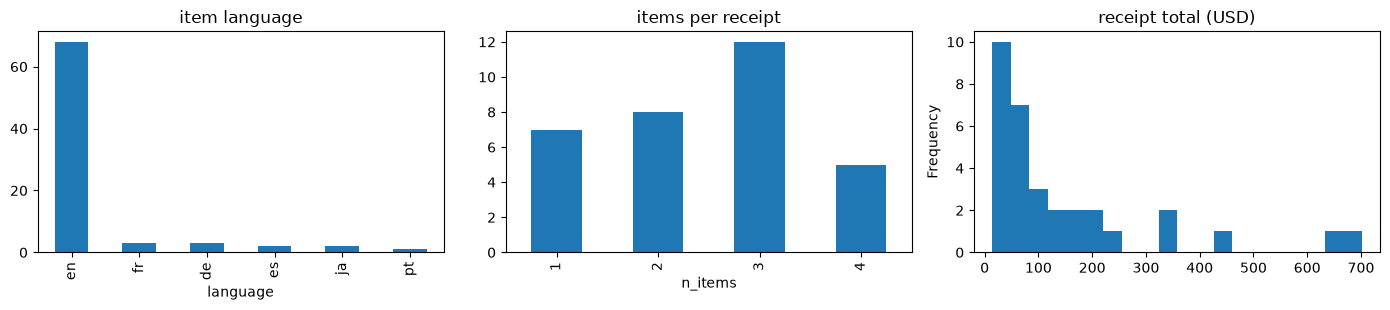

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.2))
L["language"].value_counts().plot.bar(ax=axes[0], title="item language")
R["n_items"].value_counts().sort_index().plot.bar(ax=axes[1], title="items per receipt")
R["total_amount_usd"].plot.hist(bins=20, ax=axes[2], title="receipt total (USD)")
plt.tight_layout()
print("description length (characters):", L["desc_len"].describe().round(1).to_dict())

In [11]:
print("receipt total USD:", R["total_amount_usd"].describe().round(2).to_dict())
print("line amount USD:", L["amount_usd"].describe().round(2).to_dict())
pd.crosstab(L.merge(R[["receipt_id", "currency"]], on="receipt_id")["currency"], L["language"])

receipt total USD: {'count': 32.0, 'mean': 150.92, 'std': 172.75, 'min': 14.48, '25%': 46.19, '50%': 76.5, '75%': 186.75, 'max': 701.04}
line amount USD: {'count': 79.0, 'mean': 61.13, 'std': 109.72, 'min': 3.0, '25%': 8.52, '50%': 19.0, '75%': 67.0, 'max': 601.66}


language,de,en,es,fr,ja,pt
currency,,,,,,
EUR,3,0,0,3,0,1
INR,0,3,0,0,0,0
JPY,0,0,0,0,2,0
USD,0,65,2,0,0,0


## Cross-receipt groupings that MEAL-01 / REG-02 / REG-03, HEALTH-01 and TIME-03 need

- **Employee and calendar date** for the daily meal caps (MEAL-01, REG-02, REG-03): every meal
  receipt of one employee on the same date is summed per person.
- **Trip** for HEALTH-01 (OTC medication up to $25 across all of a trip's receipts).
- **Employee, merchant name and date** for TIME-03 (split transactions).

In [12]:
MEAL_TYPES = {"Meals - Individual", "Meals - Team", "Client Entertainment"}
R["is_meal_type"] = R["submitted_expense_type"].isin(MEAL_TYPES)
day = (
    R[R["is_meal_type"]]
    .groupby(["employee_id", "date"])
    .agg(receipts=("receipt_id", "count"), ids=("receipt_id", list))
)
print(
    "employee-days with meal-type receipts:",
    len(day),
    "| with more than one receipt:",
    int((day["receipts"] > 1).sum()),
)
day[day["receipts"] > 1]

employee-days with meal-type receipts: 16 | with more than one receipt: 1


,,receipts,ids
employee_id,date,,
E-1180,2026-04-27,2,"[RCP-020, RCP-021]"


In [13]:
trips = (
    R[R["trip_id"].notna()]
    .groupby("trip_id")
    .agg(
        receipts=("receipt_id", "count"),
        nights=("trip_nights", "first"),
        employees=("employee_id", "nunique"),
        ids=("receipt_id", list),
    )
)
print(
    "trips:", len(trips), "| trips with more than one receipt:", int((trips["receipts"] > 1).sum())
)
trips.sort_values("receipts", ascending=False).head(10)

trips: 14 | trips with more than one receipt: 3


,receipts,nights,employees,ids
trip_id,,,,
TRIP-0208,3,3.0,1,"[RCP-020, RCP-021, RCP-024]"
TRIP-0091,2,3.0,1,"[RCP-001, RCP-002]"
TRIP-0122,2,5.0,1,"[RCP-009, RCP-017]"
TRIP-0097,1,2.0,1,[RCP-010]
TRIP-0106,1,2.0,1,[RCP-004]
TRIP-0104,1,3.0,1,[RCP-005]
TRIP-0118,1,2.0,1,[RCP-008]
TRIP-0131,1,2.0,1,[RCP-023]
TRIP-0201,1,2.0,1,[RCP-016]


In [14]:
split = R.groupby(["employee_id", "merchant_name", "date"]).agg(
    receipts=("receipt_id", "count"), ids=("receipt_id", list)
)
split[split["receipts"] > 1]

,,,receipts,ids
employee_id,merchant_name,date,,
E-1180,Copper Skillet,2026-04-27,2,"[RCP-020, RCP-021]"


## Domestic or international, and the euro-rate question

MEAL-01 needs the currency of the employee's home country. The data has no such field, so this
is an explicit table for the countries present. REG-03 and REG-04 need the euro rate on the
transaction date; for a non-EUR receipt of an EMEA employee that rate is not on the record
(ambiguity 1 in `policy_ambiguities.yaml`). This counts how often that happens.

In [15]:
HOME_CCY = {
    "US": "USD",
    "IN": "INR",
    "JP": "JPY",
    "SG": "SGD",
    "GB": "GBP",
    "DE": "EUR",
    "FR": "EUR",
    "NL": "EUR",
    "IE": "EUR",
    "PT": "EUR",
    "ES": "EUR",
    "CA": "CAD",
    "MX": "MXN",
    "BR": "BRL",
}
unknown = sorted(set(R["employee_country"]) - set(HOME_CCY))
print("countries without a home currency in the table:", unknown or "none")
R["home_ccy"] = R["employee_country"].map(HOME_CCY)
R["international"] = R["currency"] != R["home_ccy"]
print(pd.crosstab(R["entity"], R["international"]).to_string())
emea_non_eur = R[(R["entity"] == "EMEA") & (R["currency"] != "EUR")]
eur_dates = set(R.loc[R["currency"] == "EUR", "date"])
print(
    "EMEA receipts not in EUR:",
    len(emea_non_eur),
    "| of those, with a EUR receipt on the same date to borrow the rate from:",
    int(emea_non_eur["date"].isin(eur_dates).sum()),
)

countries without a home currency in the table: none
international  False
entity              
APAC               2
EMEA               3
GLOBAL            27
EMEA receipts not in EUR: 0 | of those, with a EUR receipt on the same date to borrow the rate from: 0


## Metadata retriever prototype

Deterministic: which rules **could** apply to a receipt, from its metadata alone, before any
item is classified. Two layers:

1. **Receipt-level triggers** that need no item categories (MCC tier, itemization, currency,
   entity, trip, time, attendee count, cross-receipt groups).
2. **Item-rule priors**: item-category rules that the merchant (MCC) or the declared expense type
   make plausible. After classification the engine adds any item rule whose category actually
   appears, so these priors only decide what is worth checking first; they never remove a rule
   the classified items trigger.

The goal is recall: a missing rule is a missed violation, an extra rule only costs a check.
There is **no evaluation here**; whether it ever misses a rule is measured later, in `eval/`.

In [16]:
ON_PREMISES = {5812, 5813, 7011}
HIGH = {m for m, t in MCC_TIER.items() if t == "high"}
MEDIUM = {m for m, t in MCC_TIER.items() if t == "medium"}
ALCOHOL_RULES = ["ALC-01", "ALC-02", "ALC-03"]

MCC_PRIORS = {
    5921: ["ALC-03"],
    5993: ["PERS-03"],
    7995: ["ENT-02"],
    7297: ["PERS-01"],
    5944: ["GIFT-01", "GIFT-04"],
    5813: ["ALC-01", "ALC-02"],
    5812: ["ALC-01", "ALC-02", "GIFT-04"],
    7011: ["ALC-01", "ALC-02", "LAUNDRY-01", "PERS-01"],
    5912: ["HEALTH-01", "PERS-01", "HOUSE-01"],
    5311: ["PERS-02", "HOUSE-01", "TECH-01", "GIFT-01", "PERS-01"],
    5411: ["ALC-03", "HOUSE-01", "PERS-01", "HEALTH-01"],
    5732: ["TECH-01", "TECH-02", "TECH-03"],
    5942: ["GIFT-01"],
    5943: ["TECH-02", "HOUSE-01"],
    5734: ["TECH-04"],
    7216: ["LAUNDRY-01"],
}
TYPE_PRIORS = {
    "Client Gifts": ["GIFT-01", "GIFT-02", "GIFT-03", "GIFT-04"],
    "Client Entertainment": ["ALC-01", "ALC-02", "ENT-01", "GIFT-04"],
    "Meals - Team": ["ALC-01", "ALC-02"],
    "Meals - Individual": ["ALC-01"],
    "Computer Equipment": ["TECH-01", "TECH-02", "TECH-03"],
    "Office Supplies": ["TECH-02", "HOUSE-01"],
    "Software": ["TECH-04"],
    "Lodging": ["LAUNDRY-01", "PERS-01"],
    "Travel - Other": ["HEALTH-01", "LAUNDRY-01", "PERS-01", "PERS-02"],
}
TIME_TYPES = {"Meals - Individual", "Lodging", "Travel - Other"}

group_size = R.groupby(["employee_id", "merchant_name", "date"])["receipt_id"].transform("count")
R["split_group"] = group_size


def eur_to_usd_rate(r) -> float | None:
    if r["currency"] == "EUR":
        return r["fx_rate_to_usd"]
    same_day = R[(R["currency"] == "EUR") & (R["date"] == r["date"])]["fx_rate_to_usd"]
    return float(same_day.iloc[0]) if len(same_day) else None


def candidates(r) -> list[str]:
    out: set[str] = set()
    mcc = int(r["mcc"])
    apac, emea = r["entity"] == "APAC", r["entity"] == "EMEA"
    meal = r["submitted_expense_type"] in MEAL_TYPES
    # Receipt-level triggers.
    if mcc in HIGH:
        out.add("MCC-01")
    if mcc in MEDIUM:
        out.add("MCC-02")
    if mcc == 5813:
        out.add("MCC-03")
    if meal:
        out.add("REG-02" if apac else "REG-03" if emea else "MEAL-01")
        if r["total_amount_usd"] > 150:
            out.add("MEAL-02")
    if not r["itemized"] and r["total_amount_usd"] > 75:
        out.add("DOC-01")
    if not (r["merchant_name"] and r["transaction_datetime"] and r["total_amount"] is not None):
        out.add("DOC-02")
    if r["itemized"]:
        out.add("DOC-03")
    if r["currency"] != "USD":
        out.add("DOC-04")
    if emea:
        rate = eur_to_usd_rate(r)
        # Above EUR 50, or unknown euro rate: keep the rule (recall first).
        if rate is None or r["total_amount_usd"] > 50 * rate:
            out.add("REG-04")
    if r["dt"].hour < 5:
        out.add("TIME-01")
    if r["submitted_expense_type"] in TIME_TYPES and pd.isna(r["trip_id"]):
        out.add("TIME-02")
    if r["split_group"] > 1:
        out.add("TIME-03")
    # Item-rule priors.
    out |= set(MCC_PRIORS.get(mcc, []))
    out |= set(TYPE_PRIORS.get(r["submitted_expense_type"], []))
    # Alcohol scope: on-premises merchants get ALC-01/02, others ALC-03; APAC gets REG-01 instead.
    if out & set(ALCOHOL_RULES) or meal:
        out -= set(ALCOHOL_RULES)
        if apac:
            out.add("REG-01")
        elif mcc in ON_PREMISES:
            out |= {"ALC-01", "ALC-02"}
        else:
            out.add("ALC-03")
    if apac and mcc == 5921:
        out.add("REG-01")
    return sorted(out)


R["candidates"] = R.apply(candidates, axis=1)
R["n_candidates"] = R["candidates"].map(len)
cand = dict(zip(R["receipt_id"], R["candidates"]))
(EXP / "policy" / "02_retriever_candidates.json").write_text(
    json.dumps(cand, indent=1, sort_keys=True)
)
print(
    f"{len(cand)} receipts; candidates per receipt: mean {R['n_candidates'].mean():.1f}, "
    f"min {R['n_candidates'].min()}, max {R['n_candidates'].max()} (of 41 rules)"
)
R[["receipt_id", "entity", "submitted_expense_type", "mcc", "n_candidates", "candidates"]]

32 receipts; candidates per receipt: mean 5.9, min 2, max 10 (of 41 rules)


,receipt_id,entity,submitted_expense_type,mcc,n_candidates,candidates
0,RCP-001,GLOBAL,Meals - Individual,5812,5,"[ALC-01, ALC-02, DOC-03, GIFT-04, MEAL-01]"
1,RCP-002,GLOBAL,Client Entertainment,5812,7,"[ALC-01, ALC-02, DOC-03, ENT-01, GIFT-04, MEAL..."
2,RCP-003,GLOBAL,Office Supplies,5943,3,"[DOC-03, HOUSE-01, TECH-02]"
3,RCP-004,GLOBAL,Meals - Team,5812,5,"[ALC-01, ALC-02, DOC-03, GIFT-04, MEAL-01]"
4,RCP-005,GLOBAL,Lodging,7011,5,"[ALC-01, ALC-02, DOC-03, LAUNDRY-01, PERS-01]"
5,RCP-006,GLOBAL,Computer Equipment,5943,5,"[DOC-03, HOUSE-01, TECH-01, TECH-02, TECH-03]"
6,RCP-007,GLOBAL,Meals - Team,5812,6,"[ALC-01, ALC-02, DOC-03, GIFT-04, MEAL-01, MEA..."
7,RCP-008,EMEA,Meals - Team,5812,6,"[ALC-01, ALC-02, DOC-03, DOC-04, GIFT-04, REG-03]"
8,RCP-009,GLOBAL,Travel - Other,7216,5,"[DOC-03, HEALTH-01, LAUNDRY-01, PERS-01, PERS-02]"
9,RCP-010,GLOBAL,Meals - Individual,5812,5,"[ALC-01, ALC-02, DOC-03, GIFT-04, MEAL-01]"


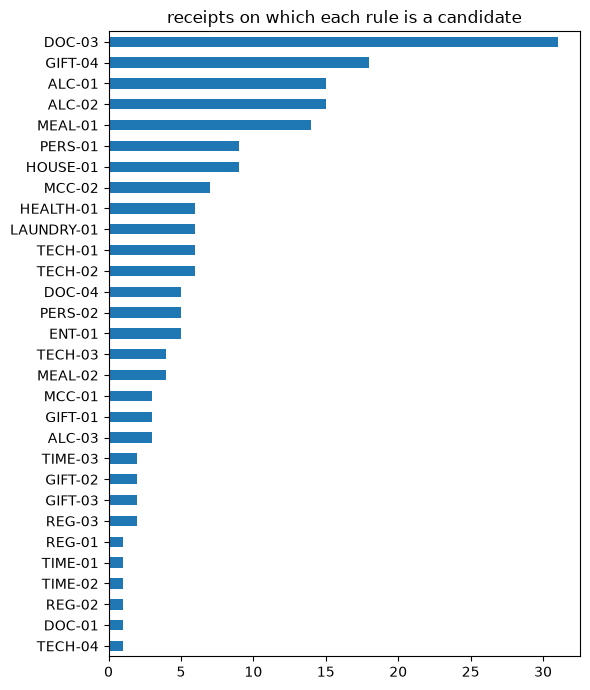

In [17]:
rule_freq = Counter(r for c in cand.values() for r in c)
pd.Series(rule_freq).sort_values().plot.barh(
    figsize=(6, 7), title="receipts on which each rule is a candidate"
)
plt.tight_layout()

## What this shows

- The receipt-level rules are fully decidable from metadata; the retriever only narrows the
  **item** rules, and the engine still adds any item rule whose category the classifier
  returns. That keeps the retriever from ever being the cause of a missed violation on its own.
- The cross-receipt groupings above are what the engine must compute before applying the daily
  meal caps, HEALTH-01 and TIME-03; they are part of the engine, not of the classifier.
- The euro-rate gap for non-EUR EMEA receipts is real in this data whenever the count above is
  non-zero; it needs Luis's decision (ambiguity 1).